In [1]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import compress_pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


In [2]:
sgc_pop = populations.SGC()
pyr_pop = populations.Pyramidal()
ds_pop = populations.DStellate()
vert_pop = populations.Tuberculoventral()

sgc_cfs = sgc_pop._get_cf_array(species='mouse')
pyr_cfs = pyr_pop._get_cf_array(species='mouse')
ds_cfs = ds_pop._get_cf_array(species='mouse')
vert_cfs = vert_pop._get_cf_array(species='mouse')

In [3]:
colors = {'pyramidal': 'tab:blue',
          'vertical': 'tab:green',
          'dstellate': 'tab:orange',
          'sgc': 'tab:purple'}

In [4]:
stimpar = {"dur": 0.26,
           "pip": 0.1,
           "start": [0.125],
           "baseline": [25, 125],
           "response": [125, 225]}

In [5]:
response_weights = {'III': {'sp': 0.00036,
                            'vp': 0.0014,
                            'dp': 0.002228},
                    'IV': {'sp': 0.00028,
                           'vp': 0.0038,
                           'dp': 0.002228}}

In [6]:
def time_weight_probability_density(spike_times, level_weights, bin_width):

    all_freqs = []
    all_weights = []

    for i, spikes in enumerate(spike_times):

        isis_ms = np.diff(spikes)  # * level_weights[i][0]
        freqs_hz = 1000.0 / isis_ms 

        isis_ms *= level_weights[i]
        all_freqs.append(freqs_hz)
        all_weights.append(isis_ms)

    all_freqs = np.concatenate(all_freqs)
    all_weights = np.concatenate(all_weights)

    all_weights = all_weights / np.sum(all_weights)

    bin_edges_hz = np.arange(0, np.max(all_freqs) + bin_width, bin_width)

    density, _ = np.histogram(all_freqs, bins=bin_edges_hz, weights=all_weights)

    density = density / np.diff(bin_edges_hz)
    bin_centers_hz = 0.5 * (bin_edges_hz[:-1] + bin_edges_hz[1:])
    
    avg_freq = np.average(all_freqs)

    return avg_freq, density, bin_centers_hz,  bin_edges_hz

# Type III

In [7]:
nreps = 5
pyr_type = 'III'

ValueError: diff requires input that is at least one dimensional

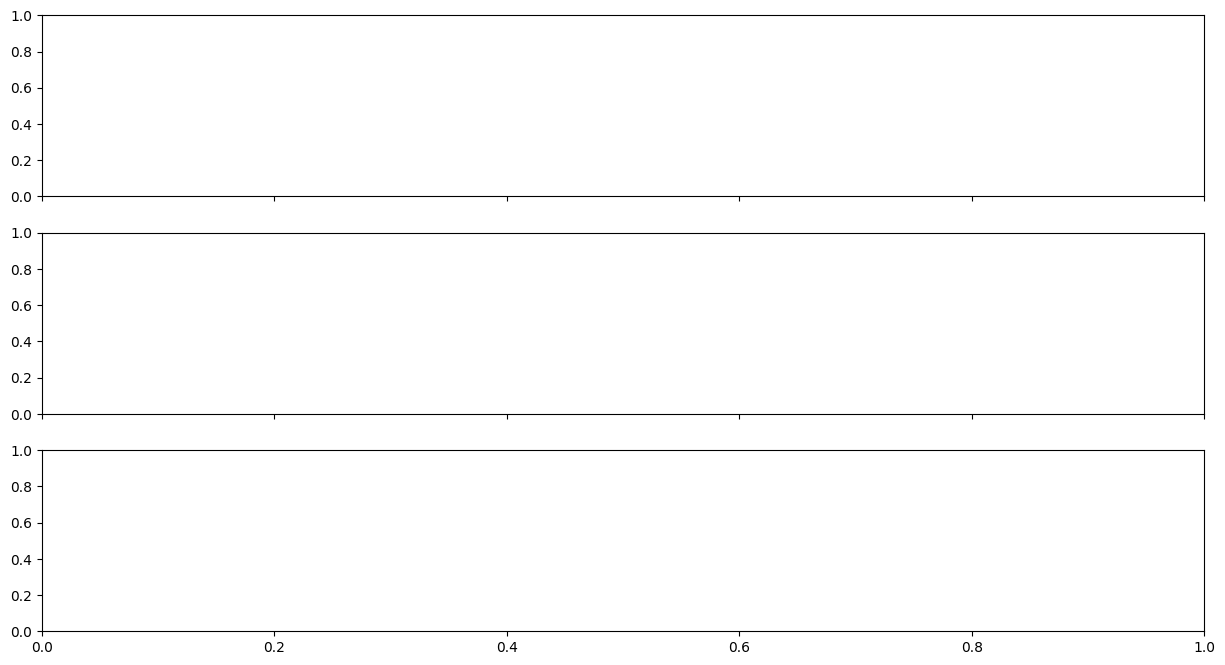

In [8]:
input_freq = 15  # kHz
pyr_cell_cfs = [15000]  # [12000, 15000, 22000]
hf = 2.0
sp_weight = response_weights[pyr_type]['sp']
vp_weight = response_weights[pyr_type]['vp']
dp_weight = response_weights[pyr_type]['dp']
cohc = 0.8
cihc = 0.8
sgn_loss = 50

norm_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-III-rate_level/665cfs-{input_freq}kHz_14ls-5nreps/NORMAL/SPx{sp_weight}_VPx{vp_weight}_DPx{dp_weight}-HFx1.0'
loss_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-III-rate_level/665cfs-{input_freq}kHz_14ls-5nreps/LOSS@15kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN/SPx{sp_weight}_VPx{vp_weight}_DPx{dp_weight}-HFx1.0'
loss_hf_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-III-rate_level/665cfs-{input_freq}kHz_14ls-5nreps/LOSS@15kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN/SPx{sp_weight}_VPx{vp_weight}_DPx{dp_weight}-HFx{hf}'

conds = ['Normal', '20% OHC + 20% IHC Loss', f'20% OHC + 20% IHC Loss, HF = {hf}']

for cf_i, pyr_cell_cf in enumerate(pyr_cell_cfs):

    fig, axs = plt.subplots(3,1,figsize=(15,8),sharex=True, sharey=True)

    for i, cond_dir in enumerate([norm_dir, loss_dir, loss_hf_dir]):

        hear_flag = '-loss' if i > 0 else ''

        # compress_pickle.load(open(cachefile, 'rb'), compression=COMPRErSSION)
        data_norm = compress_pickle.load(open(os.path.join(cond_dir,f'DATA-1fs_14dbs_{pyr_cell_cf}cf-rate_level_curveE{hear_flag}.pkl'),'rb'), compression='gzip')
        levels = data_norm['levels']

        # break
        # pyr_ids_per_band = pickle.load(open(os.path.join(cond_dir, 'pyramidal_ids_per_band.pkl'), 'rb'))
        # pyr_cfs = np.array(list(pyr_ids_per_band.keys()))
        # pyr_cell_id = pyr_ids_per_band[pyr_cfs[np.argmin(np.abs(pyr_cell_cf - pyr_cfs))]][0]

        # pyr_spont_rate = get_spontaneous_firing_rate('pyramidal', pyr_cell_id, results_df, stimpar['baseline'])

        # all_spikes = []
        # level_weights = []

        # for level in levels:
            
        #     pyr_spkt = results_df[f'f0: {int(in_freq*1e3)}  dBspl: {int(level)}'][1][0][('pyramidal', pyr_cell_id)][1]
        #     pyr_spkt = pyr_spkt[np.where((pyr_spkt > stimpar['response'][0]) & (pyr_spkt < stimpar['response'][1]))]
        #     all_spikes.append(pyr_spkt)
        #     level_weights.append(1)

        all_spikes = data_norm['matrix'].flatten()
        level_weights = np.ones(len(all_spikes))

        avg_freq, density, bin_centers, bin_edges = time_weight_probability_density(all_spikes, level_weights, bin_width=10)

        axs[i].axvline(avg_freq, color='skyblue', label='Average')
        axs[i].axvline(pyr_spont_rate, color='darkseagreen', label='Spontaneous')
        axs[i].bar(bin_centers, density, width=np.diff(bin_edges), align='center')
        axs[i].set_ylabel('Probability Density (1/Hz)')
        axs[i].set_title(conds[i])

        axs[i].legend(loc='upper right')
        # fig.suptitle(f'75% OHC Loss, HF = {hf}')
    axs[-1].set_xlabel('Frequency (Hz)')
    
    fig.suptitle(f'Type III {int(pyr_cell_cf // 1e3)}kHz CF')
    fig.tight_layout()
    # break